In [1]:
#Import Packages
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
%pip install kagglehub
import kagglehub
import sys
import statsmodels.api as sm 

#Read in Functions
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, classification_report
from sklearn.metrics import accuracy_score, confusion_matrix,precision_score, recall_score,f1_score,roc_curve, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

Note: you may need to restart the kernel to use updated packages.


In [2]:
print(pd.__version__)
print(np.__version__)
print(sklearn.__version__)
print(sys.version)

2.3.3
2.5.2
1.9.0
3.13.15 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 17:17:48) [MSC v.1942 64 bit (AMD64)]


In [3]:
#Reading Data in
path = kagglehub.dataset_download("sgpjesus/bank-account-fraud-dataset-neurips-2022",path="Base.csv")
data = pd.read_csv(path, compression="zip")

In [4]:
data.columns.tolist()

['fraud_bool',
 'income',
 'name_email_similarity',
 'prev_address_months_count',
 'current_address_months_count',
 'customer_age',
 'days_since_request',
 'intended_balcon_amount',
 'payment_type',
 'zip_count_4w',
 'velocity_6h',
 'velocity_24h',
 'velocity_4w',
 'bank_branch_count_8w',
 'date_of_birth_distinct_emails_4w',
 'employment_status',
 'credit_risk_score',
 'email_is_free',
 'housing_status',
 'phone_home_valid',
 'phone_mobile_valid',
 'bank_months_count',
 'has_other_cards',
 'proposed_credit_limit',
 'foreign_request',
 'source',
 'session_length_in_minutes',
 'device_os',
 'keep_alive_session',
 'device_distinct_emails_8w',
 'device_fraud_count',
 'month']

In [5]:
#Check for NA values
print("Number of NA Values:",data.isna().sum().sum())
#Check for Blank values
print("Number of Blank Values:",(data.astype(str).apply(lambda col: col.str.strip()) == '').sum().sum())
#Check for duplicate rows
print("Number of duplicate rows:",data.duplicated().sum())

Number of NA Values: 0
Number of Blank Values: 0
Number of duplicate rows: 0


In [6]:
#Number of bank accounts being opened
print("Number of Bank Accounts Opened:",len(data))
#Find the number of fraudulent cases
fraud = data[data['fraud_bool'] == 1]
valid = data[data['fraud_bool'] == 0]
print("Fraudulent Transactions:",len(fraud))
print("Valid Transactions:", len(valid))
# Outlier fraction, should be very low percent
outlier_fraction = len(fraud)/len(valid)
print("Outlier Fraction:", outlier_fraction)
#Fraud Rate
print('Fruad Rate:',data[data['fraud_bool'] == 1]['fraud_bool'].count() / data['fraud_bool'].count())

Number of Bank Accounts Opened: 1000000
Fraudulent Transactions: 11029
Valid Transactions: 988971
Outlier Fraction: 0.011151995356790038
Fruad Rate: 0.011029


In [7]:
# View dtype of each column, make sure they all look right
print(data.dtypes)
pd.set_option('display.max_columns', None)
data.head()

fraud_bool                            int64
income                              float64
name_email_similarity               float64
prev_address_months_count             int64
current_address_months_count          int64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                         object
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                    object
credit_risk_score                     int64
email_is_free                         int64
housing_status                       object
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                     int64
has_other_cards                 

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


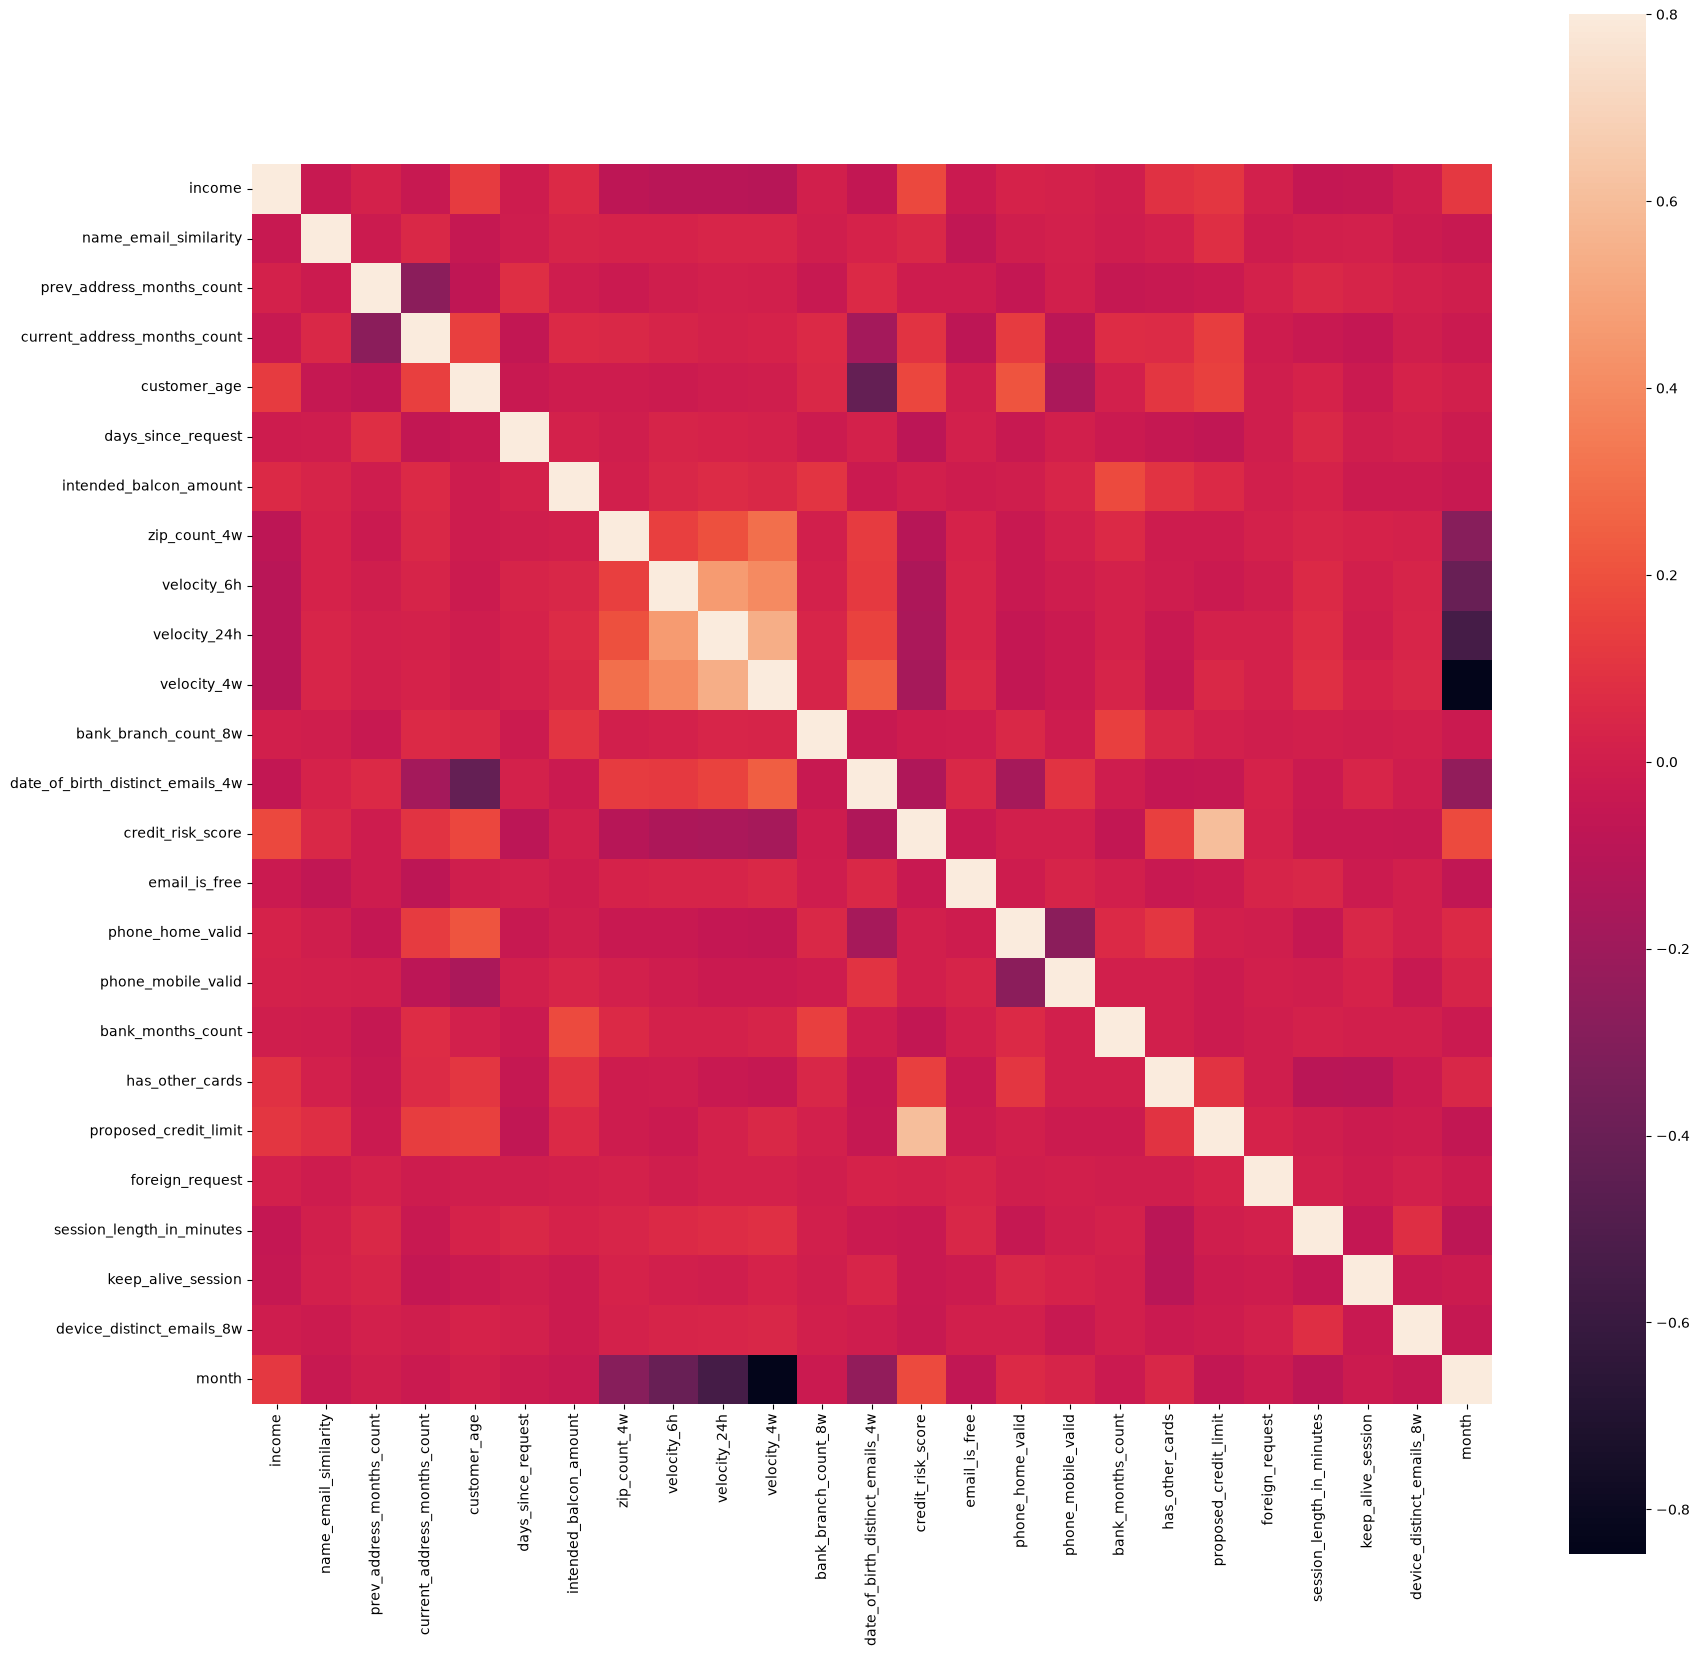

In [8]:
#Create Data frame only using numeric and boolean columns
columns = [c for c in data.columns if c not in ['fraud_bool',
                                               'payment_type',
                                               'employment_status',
                                               'housing_status',
                                                'source',
                                               'device_os',
                                               'device_fraud_count']]

X = data[columns].astype(float)   # turns True/False columns into 1.0 / 0.0

#Correlation Matrix
corrmat = X.select_dtypes(include=['number']).corr()
fig = plt.figure(figsize = (20,20))

sns.heatmap(corrmat, vmax = 0.8, square = True)
plt.show()

                                  n_outliers  pct_outliers           min  \
proposed_credit_limit                 241742         24.17  1.900000e+02   
intended_balcon_amount                222702         22.27 -1.553055e+01   
bank_branch_count_8w                  175243         17.52  0.000000e+00   
prev_address_months_count             157320         15.73 -1.000000e+00   
days_since_request                     94834          9.48  4.036860e-09   
session_length_in_minutes              78789          7.88 -1.000000e+00   
zip_count_4w                           59871          5.99  1.000000e+00   
current_address_months_count           41001          4.10 -1.000000e+00   
device_distinct_emails_8w              31933          3.19 -1.000000e+00   
date_of_birth_distinct_emails_4w        9734          0.97  0.000000e+00   
credit_risk_score                       8729          0.87 -1.700000e+02   
velocity_24h                            2917          0.29  1.300307e+03   
customer_age

income                                 Axes(0.125,0.747241;0.133621x0.132759)
name_email_similarity               Axes(0.285345,0.747241;0.133621x0.132759)
prev_address_months_count            Axes(0.44569,0.747241;0.133621x0.132759)
current_address_months_count        Axes(0.606034,0.747241;0.133621x0.132759)
customer_age                        Axes(0.766379,0.747241;0.133621x0.132759)
days_since_request                     Axes(0.125,0.587931;0.133621x0.132759)
intended_balcon_amount              Axes(0.285345,0.587931;0.133621x0.132759)
zip_count_4w                         Axes(0.44569,0.587931;0.133621x0.132759)
velocity_24h                        Axes(0.606034,0.587931;0.133621x0.132759)
bank_branch_count_8w                Axes(0.766379,0.587931;0.133621x0.132759)
date_of_birth_distinct_emails_4w       Axes(0.125,0.428621;0.133621x0.132759)
credit_risk_score                   Axes(0.285345,0.428621;0.133621x0.132759)
bank_months_count                    Axes(0.44569,0.428621;0.133

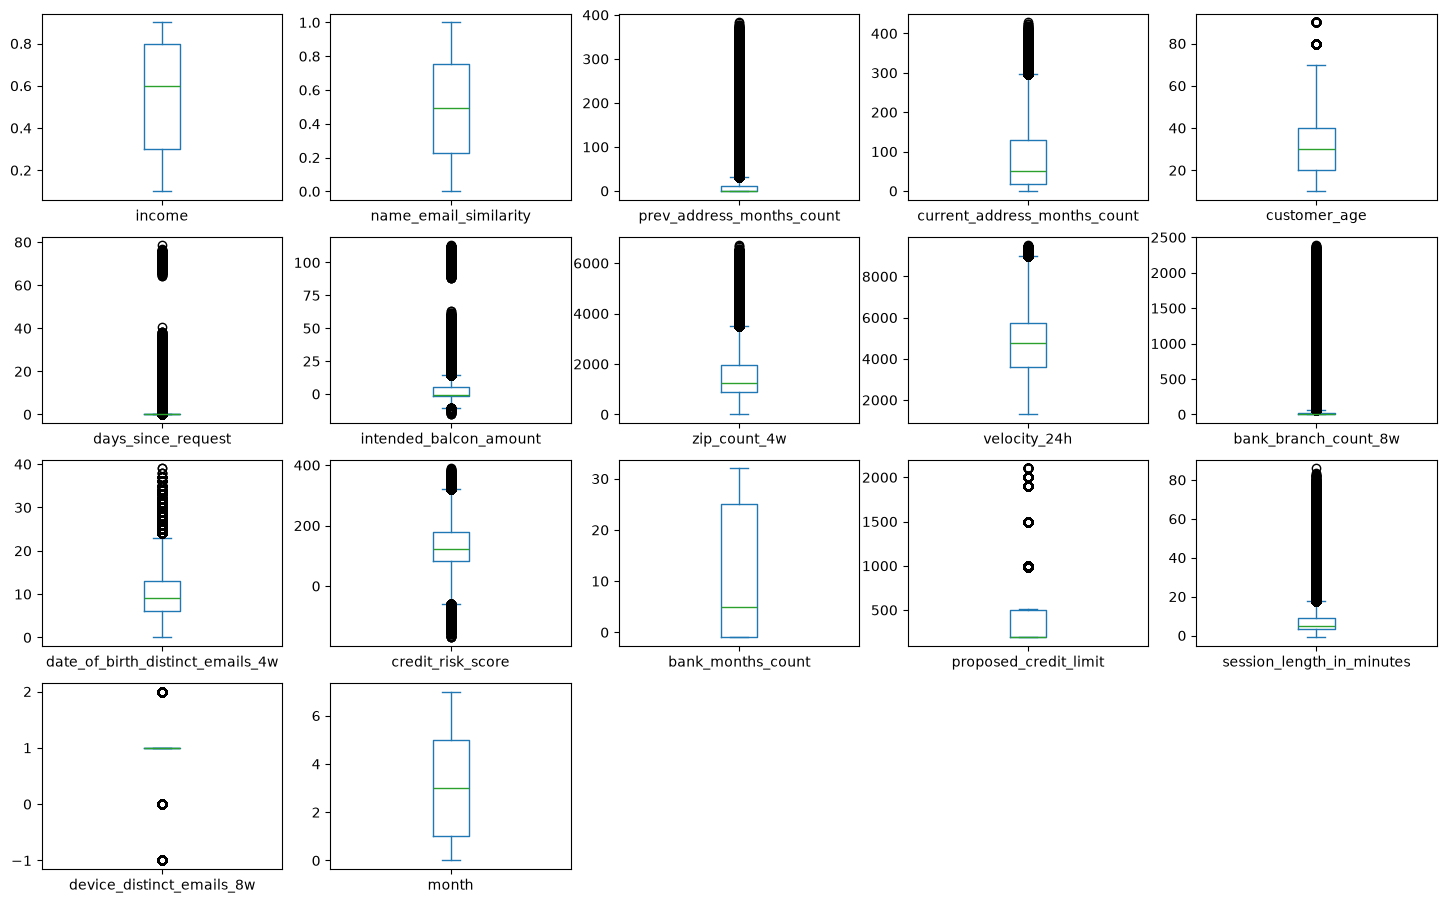

In [9]:
numeric_cols = [c for c in data.columns if c not in [
    'fraud_bool', 'device_fraud_count', 'payment_type', 'employment_status', 'housing_status', 'source', 'device_os', 'velocity_6h', 'velocity_4w'
]]
cont = [c for c in numeric_cols if data[c].nunique() > 2]
num = data[cont]

q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

is_out = (num < low) | (num > high)

summary = pd.DataFrame({
    'n_outliers': is_out.sum(),
    'pct_outliers': (is_out.mean() * 100).round(2),
    'min': num.min(),
    'p99': num.quantile(0.99),
    'max': num.max(),
}).sort_values('pct_outliers', ascending=False)
print(summary)

# Visual check, one box plot per column
num.plot(kind='box', subplots=True, layout=(5, 5), figsize=(18, 14))

In [10]:
#for c in cont:
    #out_rate = data["fraud_bool"][is_out[c]].mean()
    #print(c, round(out_rate, 4), "vs overall", round(y_train.mean(), 4))

In [11]:
sentinel_cols = ['prev_address_months_count', 'current_address_months_count',
                 'bank_months_count', 'session_length_in_minutes',
                 'device_distinct_emails_8w', 'intended_balcon_amount']

counts = (data[sentinel_cols] < 0).sum()
pct = ((data[sentinel_cols] < 0).mean() * 100).round(2)
print(pd.DataFrame({'n_negative': counts, 'pct_negative': pct}))

# Does being missing carry fraud signal?
for c in sentinel_cols:
    miss = data[c] < 0
    print(c, "fraud rate if missing:", round(data.loc[miss, 'fraud_bool'].mean(), 4),
          "| if present:", round(data.loc[~miss, 'fraud_bool'].mean(), 4))

                              n_negative  pct_negative
prev_address_months_count         712920         71.29
current_address_months_count        4254          0.43
bank_months_count                 253635         25.36
session_length_in_minutes           2015          0.20
device_distinct_emails_8w            359          0.04
intended_balcon_amount            742523         74.25
prev_address_months_count fraud rate if missing: 0.0142 | if present: 0.0031
current_address_months_count fraud rate if missing: 0.0033 | if present: 0.0111
bank_months_count fraud rate if missing: 0.0163 | if present: 0.0092
session_length_in_minutes fraud rate if missing: 0.0089 | if present: 0.011
device_distinct_emails_8w fraud rate if missing: 0.0111 | if present: 0.011
intended_balcon_amount fraud rate if missing: 0.0131 | if present: 0.005


In [12]:
# def box_tidwell(df, target, cols, sample=200_000, seed=27695):
#     cols = [c for c in cols if df[c].nunique() > 5 and not c.endswith('_missing')]
#     d_all = pd.concat([df[cols], target], axis=1).dropna()
#     d_all = d_all.sample(min(sample, len(d_all)), random_state=seed)
#     rows = []
#     for c in cols:
#         x = d_all[c]
#         x = x - x.min() + 1          # shift so the log is defined
#         Xd = sm.add_constant(pd.DataFrame({'x': x, 'x_lnx': x * np.log(x)}))
#         res = sm.Logit(d_all[target.name], Xd).fit(disp=0)
#         rows.append((c, res.params['x_lnx'], res.pvalues['x_lnx']))
#     out = pd.DataFrame(rows, columns=['feature', 'coef', 'p_value'])
#     out['flag'] = out['p_value'] < 0.05 / len(out)   # Bonferroni threshold
#     return out.sort_values('p_value')

# print(box_tidwell(X_train, y_train, numeric_cols))

In [13]:
# #Using Categorical Columns and setting the class imbalance parameter
# #Categorical Columns: Merchant Category, Card Type, Authentication Method, Channel, Device Type
# #Filter Columns
# cat_cols = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
# numeric_cols = [c for c in data.columns if c not in [
#     'fraud_bool', 'device_fraud_count', 'payment_type', 'employment_status', 'housing_status', 'source', 'device_os', 'velocity_6h', 'velocity_4w'
# ]]

# X = data.astype({'email_is_free':int, 
#                  'phone_home_valid':int, 
#                  'phone_mobile_valid':int,
#                  'has_other_cards':int, 
#                  'foreign_request':int,
#                 'keep_alive_session':int,
#                 'device_distinct_emails_8w':int,})  # turns True/False columns into 1.0 / 0.0
# y = data["fraud_bool"]

# #Split the data, build training, test, and validation sets (Want ~ 70%, 15%, 15% split)
#     #Split into test and temporary sets
# X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=27695)
#     #Split temporary set into training and validation sets
# X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size = 0.15/0.85, stratify=y_temp, random_state=27695)

# #Encode
# encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
# X_train_cat = encoder.fit_transform(X_train[cat_cols])
# X_test_cat = encoder.transform(X_test[cat_cols])
# X_val_cat = encoder.transform(X_val[cat_cols])

# #Scale Numeric columns
# scaler = StandardScaler()
# X_train_scaled_nums = scaler.fit_transform(X_train[numeric_cols].values)
# X_test_scaled_nums = scaler.transform(X_test[numeric_cols].values)
# X_val_scaled_nums = scaler.transform(X_val[numeric_cols].values)

# #Combine categorical and numerical features
# X_train_full = np.hstack([X_train_scaled_nums, X_train_cat])
# X_test_full = np.hstack([X_test_scaled_nums, X_test_cat])
# X_val_full = np.hstack([X_val_scaled_nums, X_val_cat])


# #Testing model on Validation Data
# model = LogisticRegression(class_weight='balanced', max_iter=10000)
# model.fit(X_train_full, y_train)
# y_val_pred = model.predict(X_val_full)
# y_val_proba = model.predict_proba(X_val_full)[:, 1]
# print("Logistic Regression Accuracy:", accuracy_score(y_val, y_val_pred))
# print(classification_report(y_val, y_val_pred))
# print("ROC AUC:", roc_auc_score(y_val, y_val_proba))
# print("PR AUC:", average_precision_score(y_val, y_val_proba))
# print("Fraud rate in validation set:", y_val.mean())


In [14]:
# #Changing Decision Threshold 
# # Instead of retraining, keep the current model and lower the probability barrier to mark fraud.
# print("\n--- Testing Post-Processing Probability Thresholds ---")

# # Train one baseline balanced model
# base_model = LogisticRegression(class_weight='balanced', max_iter=1000)
# base_model.fit(X_train_full, y_train)

# # Get predicted fraud probabilities
# val_probs = base_model.predict_proba(X_val_full)[:, 1]

# # Move the threshold down from the default 0.50
# for threshold in [0.50, 0.45, 0.40, 0.35, 0.34, 0.33, 0.32, 0.32, 0.30]:
#     threshold_preds = (val_probs >= threshold).astype(int)
    
#     t_recall = recall_score(y_val, threshold_preds)
#     t_precision = precision_score(y_val, threshold_preds)
    
#     print(f"Decision Threshold: {threshold:.2f}")
#     print(f" -> Val Recall: {t_recall:.3f} | Val Precision: {t_precision:.3f}")

In [15]:
# #Using Decision Threshold of 0.3
# model = LogisticRegression(class_weight='balanced', max_iter=10000)
# model.fit(X_train_full, y_train)
# threshold = 0.3
# y_val_proba = model.predict_proba(X_val_full)[:, 1]
# y_val_pred = (y_val_proba >= threshold).astype(int) 
# print("Logistic Regression Accuracy:", accuracy_score(y_val, y_val_pred))
# print(classification_report(y_val, y_val_pred))
# print("ROC AUC:", roc_auc_score(y_val, y_val_proba))
# print("PR AUC:", average_precision_score(y_val, y_val_proba))
# print("Fraud rate in validation set:", y_val.mean())

# # Testing model on Test Data
# model = LogisticRegression(class_weight = 'balanced',max_iter=10000)
# model.fit(X_train_full, y_train)
# y_test_proba = model.predict_proba(X_test_full)[:, 1]
# y_test_pred = (y_test_proba >= threshold).astype(int)
# print("Logistic Regression Accuracy:", accuracy_score(y_test, y_test_pred))
# print('Total Fraud in Test set:',y_test.sum())
# print('Total Transactions in Test Set:',y_test.count())

# #Evaluate the model using PR-AUC and ROC-AUC
# print(classification_report(y_test, y_test_pred))
# print("ROC AUC:", roc_auc_score(y_test, y_test_proba))
# print("PR AUC:", average_precision_score(y_test, y_test_proba))
# print("Fraud rate in test set:", y_test.mean())

In [16]:
# cm = confusion_matrix(y_test, y_test_pred, labels=[1, 0])
# disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fraudulent', 'Legitimate'])
# disp.plot(cmap=plt.cm.Blues, text_kw={'fontsize': 15})
# plt.title("Confusion Matrix for Test Set")
# #plt.savefig("confusion_matrix_TEST.png", dpi=300, bbox_inches="tight")
# plt.show()

In [17]:
# print('Total training set transactions',X_train['fraud_bool'].count()) 
# print('# of Fraud transactions in Training set:',(X_train['fraud_bool'] == 1).sum()) # fraud in train

# print('Total Validation set:', X_val['fraud_bool'].count())
# print('# of Fraud transactions in Validation set:',(X_val['fraud_bool'] == 1).sum())

# print('total test transactions', X_test['fraud_bool'].count())
# print('# of Fraud transactions in Test set:',(X_test['fraud_bool'] == 1).sum()) # fraud in test 



In [18]:
# from sklearn.metrics import PrecisionRecallDisplay
# fig, ax = plt.subplots(figsize=(7, 5))
# PrecisionRecallDisplay.from_predictions(y_test, y_test_proba, ax=ax, name="Logistic Regression")
# ax.axhline(y_test.mean(), color="gray", linestyle="--", label=f"No skill ({y_test.mean():.3f})")
# p = precision_score(y_test, y_test_pred)
# r = recall_score(y_test, y_test_pred)
# ax.scatter(r, p, color="red", zorder=5, label="Threshold = 0.3")
# ax.axvline(r, color="red", linestyle="--", label=f"Decision threshold = 0.3 (Recall = {r:.2f})")
# ax.legend()
# ax.set_title("Precision-Recall Curve")
# ax.set_xlabel("Recall")
# ax.set_ylabel("Precision")
# ax.legend()
# ax.grid(True)
# plt.savefig("Precision-Recall Curve TEST.png", dpi=300,bbox_inches="tight")
# plt.show()

In [19]:
# ---------- 1. Missing value codes ----------
sentinel_cols = ['prev_address_months_count', 'current_address_months_count',
                 'bank_months_count', 'session_length_in_minutes',
                 'device_distinct_emails_8w', 'intended_balcon_amount']
indicator_cols = ['prev_address_months_count', 'intended_balcon_amount',
                  'bank_months_count']

df = data.copy()

# Indicators first: 1 if the value was a negative code (or is already NaN)
for c in indicator_cols:
    df[c + '_missing'] = ((df[c] < 0) | df[c].isna()).astype(int)

# Convert the codes to NaN. Cast to float first so NaN can be stored.
for c in sentinel_cols:
    df[c] = df[c].astype('float64')
    df.loc[df[c] < 0, c] = np.nan

# ---------- 2. Column lists ----------
cat_cols = ['payment_type', 'employment_status', 'housing_status',
            'source', 'device_os']
drop_cols = ['fraud_bool', 'device_fraud_count', 'month', 'velocity_6h', 'velocity_4w']
numeric_cols = [c for c in df.columns if c not in cat_cols + drop_cols]

# Turn True/False columns into 1/0
bool_cols = df[numeric_cols].select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)

X = df[numeric_cols + cat_cols]
y = df['fraud_bool']

# ---------- 3. Checks (run these before modeling) ----------
print("Non numeric columns (should be empty):",
      X[numeric_cols].select_dtypes(exclude='number').columns.tolist())
print("NaN counts (should be nonzero only for the six converted columns):")
print(X[numeric_cols].isna().sum()[lambda s: s > 0])
print("Indicator means:")
print(X[[c + '_missing' for c in indicator_cols]].mean().round(4))

# ---------- 4. Split ----------
X_temp, X_test, y_temp, y_test = train_test_split( X, y, test_size=0.15, stratify=y, random_state=27695)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.15/0.85, stratify=y_temp, random_state=27695)

# ---------- 5. Preprocessing and model in one pipeline ----------
num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])
model = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=10000)),
])

model.fit(X_train, y_train)

# ---------- 6. Validation results ----------
y_val_pred = model.predict(X_val)
y_val_proba = model.predict_proba(X_val)[:, 1]
print("Accuracy:", accuracy_score(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))
print("ROC AUC:", roc_auc_score(y_val, y_val_proba))
print("PR AUC:", average_precision_score(y_val, y_val_proba))
print("Fraud rate in validation set:", y_val.mean())

Non numeric columns (should be empty): []
NaN counts (should be nonzero only for the six converted columns):
prev_address_months_count       712920
current_address_months_count      4254
intended_balcon_amount          742523
bank_months_count               253635
session_length_in_minutes         2015
device_distinct_emails_8w          359
dtype: int64
Indicator means:
prev_address_months_count_missing    0.7129
intended_balcon_amount_missing       0.7425
bank_months_count_missing            0.2536
dtype: float64
Accuracy: 0.8062133333333333
              precision    recall  f1-score   support

           0       1.00      0.81      0.89    148346
           1       0.04      0.81      0.08      1654

    accuracy                           0.81    150000
   macro avg       0.52      0.81      0.49    150000
weighted avg       0.99      0.81      0.88    150000

ROC AUC: 0.8835749868142994
PR AUC: 0.14317941370338613
Fraud rate in validation set: 0.011026666666666667


In [20]:
from sklearn.metrics import recall_score, precision_score

print("\n--- Testing Post Processing Probability Thresholds ---")

# Reuse the fitted pipeline. It imputes, scales, and encodes on its own.
val_probs = model.predict_proba(X_val)[:, 1]

for threshold in [0.50, 0.45, 0.40, 0.35, 0.34, 0.33, 0.32, 0.31, 0.30]:
    threshold_preds = (val_probs >= threshold).astype(int)

    t_recall = recall_score(y_val, threshold_preds)
    t_precision = precision_score(y_val, threshold_preds)
    flagged = 100 * threshold_preds.mean()

    print(f"Decision Threshold: {threshold:.2f}")
    print(f" -> Val Recall: {t_recall:.3f} | Val Precision: {t_precision:.3f} | Flagged: {flagged:.1f} percent")


--- Testing Post Processing Probability Thresholds ---
Decision Threshold: 0.50
 -> Val Recall: 0.805 | Val Precision: 0.044 | Flagged: 20.1 percent
Decision Threshold: 0.45
 -> Val Recall: 0.831 | Val Precision: 0.039 | Flagged: 23.3 percent
Decision Threshold: 0.40
 -> Val Recall: 0.866 | Val Precision: 0.035 | Flagged: 27.0 percent
Decision Threshold: 0.35
 -> Val Recall: 0.894 | Val Precision: 0.032 | Flagged: 31.2 percent
Decision Threshold: 0.34
 -> Val Recall: 0.898 | Val Precision: 0.031 | Flagged: 32.1 percent
Decision Threshold: 0.33
 -> Val Recall: 0.899 | Val Precision: 0.030 | Flagged: 33.0 percent
Decision Threshold: 0.32
 -> Val Recall: 0.903 | Val Precision: 0.029 | Flagged: 34.0 percent
Decision Threshold: 0.31
 -> Val Recall: 0.906 | Val Precision: 0.029 | Flagged: 35.0 percent
Decision Threshold: 0.30
 -> Val Recall: 0.913 | Val Precision: 0.028 | Flagged: 36.1 percent


In [21]:
print('Total training set transactions:', len(y_train))
print('# of Fraud transactions in Training set:', y_train.sum())

print('Total validation set transactions:', len(y_val))
print('# of Fraud transactions in Validation set:', y_val.sum())

print('Total test set transactions:', len(y_test))
print('# of Fraud transactions in Test set:', y_test.sum())

Total training set transactions: 700000
# of Fraud transactions in Training set: 7721
Total validation set transactions: 150000
# of Fraud transactions in Validation set: 1654
Total test set transactions: 150000
# of Fraud transactions in Test set: 1654


In [22]:
def box_tidwell(df, target, cols, sample=200_000, seed=27695):
    cols = [c for c in cols if df[c].nunique() > 5 and not c.endswith('_missing')]
    d_all = pd.concat([df[cols], target], axis=1).dropna()
    d_all = d_all.sample(min(sample, len(d_all)), random_state=seed)
    rows = []
    for c in cols:
        x = d_all[c]
        x = x - x.min() + 1          # shift so the log is defined
        Xd = sm.add_constant(pd.DataFrame({'x': x, 'x_lnx': x * np.log(x)}))
        res = sm.Logit(d_all[target.name], Xd).fit(disp=0)
        rows.append((c, res.params['x_lnx'], res.pvalues['x_lnx']))
    out = pd.DataFrame(rows, columns=['feature', 'coef', 'p_value'])
    out['flag'] = out['p_value'] < 0.05 / len(out)   # Bonferroni threshold
    return out.sort_values('p_value')

print(box_tidwell(X_train, y_train, numeric_cols))

                             feature      coef   p_value   flag
10  date_of_birth_distinct_emails_4w  0.151047  0.043413  False
13             proposed_credit_limit  0.001203  0.110504  False
12                 bank_months_count -0.061375  0.129513  False
11                 credit_risk_score  0.013349  0.136789  False
14         session_length_in_minutes -0.034023  0.209122  False
3       current_address_months_count -0.006274  0.212416  False
5                 days_since_request -0.022934  0.214083  False
9               bank_branch_count_8w  0.000821  0.397670  False
1              name_email_similarity  4.332153  0.423226  False
2          prev_address_months_count -0.003746  0.476103  False
7                       zip_count_4w  0.000218  0.529591  False
6             intended_balcon_amount -0.007685  0.611805  False
8                       velocity_24h -0.000132  0.712932  False
0                             income -1.707016  0.785154  False
4                       customer_age  0.

In [23]:
def box_tidwell_each(df, target, cols, max_rows=200_000, seed=27695):
    rows = []
    for c in cols:
        d = pd.DataFrame({'x': df[c], 'y': target}).dropna()   # this feature's own non missing rows
        if d['x'].nunique() <= 5:
            continue
        d = d.sample(min(max_rows, len(d)), random_state=seed)
        x = d['x'] - d['x'].min() + 1                           # shift so the log is defined
        Xd = sm.add_constant(pd.DataFrame({'x': x, 'x_lnx': x * np.log(x)}))
        res = sm.Logit(d['y'], Xd).fit(disp=0)
        rows.append((c, len(d), int(d['y'].sum()), res.params['x_lnx'], res.pvalues['x_lnx']))
    out = pd.DataFrame(rows, columns=['feature', 'n_rows', 'n_fraud', 'coef', 'p_value'])
    out['flag'] = out['p_value'] < 0.05 / len(out)              # Bonferroni cutoff
    return out.sort_values('p_value')

cont_cols = [c for c in numeric_cols if not c.endswith('_missing')]
print(box_tidwell_each(X_train, y_train, cont_cols))

                             feature  n_rows  n_fraud      coef       p_value  \
3       current_address_months_count  200000     2243 -0.011055  1.335682e-69   
10  date_of_birth_distinct_emails_4w  200000     2218  0.168832  5.302179e-44   
11                 credit_risk_score  200000     2218  0.016267  2.608409e-28   
13             proposed_credit_limit  200000     2218  0.001054  3.916035e-20   
1              name_email_similarity  200000     2218  6.965466  1.935384e-15   
9               bank_branch_count_8w  200000     2218  0.001179  1.725066e-14   
0                             income  200000     2218  7.933606  3.198915e-14   
7                       zip_count_4w  200000     2218 -0.000213  9.324993e-04   
12                 bank_months_count  200000     1883  0.022833  1.057011e-03   
6             intended_balcon_amount  180231      869  0.009805  4.169204e-03   
14         session_length_in_minutes  200000     2211  0.011554  1.377847e-02   
2          prev_address_mont

In [ ]:
threshold = 0.31   # final threshold chosen on the validation set
y_test_proba = model.predict_proba(X_test)[:, 1]          # pass raw X_test, the pipeline preprocesses it
y_test_pred = (y_test_proba >= threshold).astype(int)
cm = confusion_matrix(y_test, y_test_pred, labels=[1, 0])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Fraudulent', 'Legitimate'])
disp.plot(cmap=plt.cm.Blues, text_kw={'fontsize': 15}, values_format='d')
plt.title(f"Confusion Matrix for Test Set (Threshold = {threshold})")
#plt.savefig("confusion_matrix_TEST.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
threshold = 0.31   # final threshold chosen on the validation set
y_test_proba = model.predict_proba(X_test)[:, 1]          # pass raw X_test, the pipeline preprocesses it
y_test_pred = (y_test_proba >= threshold).astype(int)
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_test, y_test_proba, ax=ax, name="Logistic Regression")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label=f"No skill ({y_test.mean():.3f})")
p = precision_score(y_test, y_test_pred)
r = recall_score(y_test, y_test_pred)
ax.scatter(r, p, color="red", zorder=5, label=f"Threshold = {threshold} (Precision = {p:.2f})")
ax.axvline(r, color="red", linestyle="--", label=f"Recall = {r:.2f}")
ax.set_title("Precision Recall Curve for Test Set")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(True)
#plt.savefig("precision_recall_curve_TEST.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
from sklearn.metrics import recall_score, precision_score

print("\n--- Testing Post Processing Probability Thresholds ---")

# Reuse the fitted pipeline. It imputes, scales, and encodes on its own.
val_probs = model.predict_proba(X_val)[:, 1]

for threshold in [0.50, 0.45, 0.40, 0.35, 0.34, 0.33, 0.32, 0.31, 0.30]:
    threshold_preds = (val_probs >= threshold).astype(int)

    t_recall = recall_score(y_val, threshold_preds)
    t_precision = precision_score(y_val, threshold_preds)
    flagged = 100 * threshold_preds.mean()

    print(f"Decision Threshold: {threshold:.2f}")
    print(f" -> Val Recall: {t_recall:.3f} | Val Precision: {t_precision:.3f} | Flagged: {flagged:.1f} percent")